   # Trabajo Práctico Final: extensión de Hidalgo et al. (2007)
   Matías Andaluz — M37 Ciencia de Datos, Redes y Sistemas Complejos (FCE-UBA)

   Datos: [Harvard Growth Lab, International Trade Data (HS92)](https://dataverse.harvard.edu/dataset.xhtml?persistentId=doi:10.7910/DVN/T4CHWJ)

# Datos y ventaja comparativa revelada


In [1]:
# =============================================================================
# Descarga y carga de datos
# =============================================================================
!wget -q --show-progress "https://dataverse.harvard.edu/api/access/datafile/13685110" -O /content/hs92_4digit.csv
!pip install -q ecomplexity

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from ecomplexity import ecomplexity, proximity

trade = pd.read_csv(
    '/content/hs92_4digit.csv',
    usecols=['year', 'country_iso3_code', 'product_hs92_code', 'export_value'],
    dtype=str, keep_default_na=False
)
trade = trade.rename(columns={'country_iso3_code': 'loc',
                              'product_hs92_code': 'prod',
                              'export_value': 'val'})
trade['year'] = trade['year'].astype(int)

# Años del análisis:
# - Serie 2005–2022: un mapa por año para evaluar la estabilidad del espacio de
#   producto. Empieza en 2005, donde termina el análisis de Hidalgo (2009).
#   incluye la crisis de 2008–2009, shock
#   conocido que permite verificar si las distancias detectan cambios de
#   estructura cuando ocurren (y no solo usamos años tranquilos).
# - 2017 y 2022: diversificación (mapa de 2017, transiciones hasta 2022).

AÑOS_SERIE = list(range(2005, 2023))
T0, T1 = 2017, 2022

trade = trade[trade['year'].isin(AÑOS_SERIE)].copy()
trade['val'] = pd.to_numeric(trade['val'], errors='coerce').fillna(0)

trade_cols = {'time': 'year', 'loc': 'loc', 'prod': 'prod', 'val': 'val'}

# Años de la diversificación
data = trade[trade['year'].isin([T0, T1])].copy()

print("Registros por año en la serie:")
print(trade.groupby('year').size().to_string())
print("\nDuplicados por (year, loc, prod):", trade.duplicated(subset=['year', 'loc', 'prod']).sum())

/content/hs92_4digi 100%[===================>] 430.82M  88.9MB/s    in 5.2s    
Registros por año en la serie:
year
2005    223898
2006    227130
2007    229775
2008    230457
2009    229369
2010    229883
2011    231380
2012    232436
2013    233271
2014    232739
2015    232226
2016    232239
2017    233531
2018    233917
2019    232848
2020    230045
2021    231613
2022    232693

Duplicados por (year, loc, prod): 0


In [2]:
# =============================================================================
# Control de calidad de los datos por año
# =============================================================================
# Registros con exportación positiva, países y valor exportado por año, con su
# variación porcentual respecto del año anterior.
chk = pd.read_csv('/content/hs92_4digit.csv',
                  usecols=['year', 'country_iso3_code', 'product_hs92_code', 'export_value'],
                  dtype={'country_iso3_code': str, 'product_hs92_code': str},
                  keep_default_na=False)
chk['export_value'] = pd.to_numeric(chk['export_value'], errors='coerce').fillna(0)
pos_chk = chk[chk['year'].between(2005, 2024) & (chk['export_value'] > 0)]

resumen = pos_chk.groupby('year').agg(
    registros=('export_value', 'size'),
    paises=('country_iso3_code', 'nunique'),
    comercio_miles_mm=('export_value', lambda s: s.sum() / 1e9))
resumen['var_registros_%'] = resumen['registros'].pct_change() * 100
resumen['var_comercio_%'] = resumen['comercio_miles_mm'].pct_change() * 100

print(resumen.round({'registros': 0, 'paises': 0, 'comercio_miles_mm': 0,
                     'var_registros_%': 1, 'var_comercio_%': 1}).to_string())

del chk, pos_chk

      registros  paises  comercio_miles_mm  var_registros_%  var_comercio_%
year                                                                       
2005     146722     224             9743.0              NaN             NaN
2006     150735     226            11239.0              2.7            15.4
2007     153854     226            13075.0              2.1            16.3
2008     155124     226            14917.0              0.8            14.1
2009     154002     226            11549.0             -0.7           -22.6
2010     153884     226            14007.0             -0.1            21.3
2011     155311     228            16849.0              0.9            20.3
2012     154980     229            16910.0             -0.2             0.4
2013     154136     230            17286.0             -0.5             2.2
2014     154246     230            17352.0              0.1             0.4
2015     153220     230            15085.0             -0.7           -13.1
2016     152

La tabla tiene en cuenta "registros", que mide la variedad de lo que exportan los países (pares país–producto con exportación positiva), y "comercio", que mide el valor y se mueve con cantidades y precios. También muestra la variación de cada uno respecto al año anterior.
- 2006–2008: los registros y el valor crecen con los mismos 226 países, es decir, más variedad y más valor por país, lo que coincide con la expansión de las cadenas de valor (hasta 2008).
- En 2009 el valor cae 22,6 % y los registros menos de 1 %. En 2015–2016 el valor cae 13,1 % con registros estables, lo que coincide con la baja de precios de los productos básicos. En 2020 caen ambos (pandemia) y se recuperan en 2021.
- 2022: el valor sigue subiendo (11,5 %) con registros casi estables (0,6 %), lo que sugiere un efecto de precios. Por eso el estudio de relatedness incluye un control sin productos primarios.
- 2024: los registros caen 4,8 % (más que en 2020) mientras el valor sube poco. Una caída de variedad sin caída de valor podría indicar reportes incompletos, no un cambio económico. El [Atlas de Complejidad Económica](https://atlas.hks.harvard.edu/data-downloads/), origen de los datos, aclara que sus archivos se actualizan para incorporar reportes revisados de los países, así que los años más recientes todavía pueden cambiar. Tomo 2022 como año final: el mapa se mide en 2017, último año previo a las tensiones comerciales, y con un horizonte de cinco años, como en Hidalgo et al. (2007), el período termina en 2022. Usar 2023 obligaría a medir el mapa en 2018, con el conflicto comercial ya empezado.
- Los países pasan de 224 a 230; la serie usa un panel fijo de 223 países: los que exportan en todos los años entre 2005 y 2022


In [3]:
# =============================================================================
# RCA (ventaja comparativa revelada) y matriz de especialización Mcp
# =============================================================================
# ecomplexity completa con cero las combinaciones país–producto sin
# exportaciones, así que el panel queda en 230 países x 1243 productos.
# Estos 230 países se usan para el mapa de 2017 y la diversificación; la serie
# 2005–2022 (Estudio de estabilidad) usa un panel fijo de 223 países que exportan en todos los años.
eci_data = ecomplexity(data[data['year'].isin([2017, 2022])], trade_cols)

data_2017 = eci_data[eci_data['year'] == 2017].copy()
data_2022 = eci_data[eci_data['year'] == 2022].copy()

data_2017['mcp'] = (data_2017['rca'] >= 1).astype(int)
data_2022['mcp'] = (data_2022['rca'] >= 1).astype(int)

for año, d_ in [(2017, data_2017), (2022, data_2022)]:
    print(f"{año}: {d_['mcp'].sum()} pares con RCA>=1 de {len(d_)} "
          f"({d_['mcp'].mean()*100:.1f} %)")

2017
Percentage of pairs compared that meet log-supermodularity condition: 29.16%


/usr/local/lib/python3.13/dist-packages/ecomplexity/ecomplexity.py:252: UserWarning: Year 2017: Log-supermodularity condition is not fully satisfied (29.16% of pairs compared satisfy this condition). The ECI and PCI values may not be a true representation of the complexity. More details at: https://growthlab.hks.harvard.edu/publications/structural-ranking-economic-complexity
  warnings.warn(


2022
Percentage of pairs compared that meet log-supermodularity condition: 19.45%


/usr/local/lib/python3.13/dist-packages/ecomplexity/ecomplexity.py:252: UserWarning: Year 2022: Log-supermodularity condition is not fully satisfied (19.45% of pairs compared satisfy this condition). The ECI and PCI values may not be a true representation of the complexity. More details at: https://growthlab.hks.harvard.edu/publications/structural-ranking-economic-complexity
  warnings.warn(


2017: 30819 pares con RCA>=1 de 285890 (10.8 %)
2022: 30425 pares con RCA>=1 de 285661 (10.7 %)



En 2017, de los 285.890 pares país–producto posibles (230 países por 1243 productos), 30.819 cumplen esa condición, el 10,8 %. En 2022 son el 10,7 %. O sea, cada país se destaca, en promedio, en uno de cada diez productos, y eso casi no cambió en cinco años. En 2022 hay algunos pares menos porque las máquinas de escribir (8469) ya no se exportan.


#Espacio de Producto en 2017

In [4]:
# =============================================================================
# Matriz de proximidad φ (2017)
# =============================================================================
# La proximidad φ_ij mide qué tan seguido dos productos se exportan juntos con
# ventaja comparativa. Si dos productos usan capacidades parecidas (conocimientos,
# infraestructura, instituciones), los países que hacen uno tienden a hacer el
# otro. Tomar el mínimo evita que un producto exportado por un solo país
# aparezca cerca de todos.

prox = proximity(data[data['year'] == T0], trade_cols)

# Se excluye la diagonal (φ_ii = 1 por construcción, no dice nada entre productos distintos)
prox = prox[prox['prod_1'] != prox['prod_2']].copy()
prox['proximity'] = pd.to_numeric(prox['proximity'], errors='coerce')

# Si hubiera duplicados, pivot_table los promediaría sin avisar
print("Duplicados por (year, prod_1, prod_2):",
      prox.duplicated(subset=['year', 'prod_1', 'prod_2']).sum())

def matriz_phi(prox_año, productos=None):
    """Matriz cuadrada producto x producto. proximity() ya trae (i,j) y (j,i),
    por eso solo se pivotea y no se suma la transpuesta."""
    m = prox_año.pivot_table(index='prod_1', columns='prod_2',
                             values='proximity', fill_value=0)
    if productos is None:
        productos = sorted(set(m.index) | set(m.columns))
    return m.reindex(index=productos, columns=productos, fill_value=0)

prox_2017 = prox[prox['year'] == 2017]
phi_matrix = matriz_phi(prox_2017)
todos_los_productos = list(phi_matrix.index)   # universo fijo de productos (2017)
N = len(todos_los_productos)

print("phi_matrix 2017:", phi_matrix.shape)
print("Máxima diferencia φ_ij vs φ_ji (debe ser ~0):",
      np.abs(phi_matrix.values - phi_matrix.values.T).max())

2017
Duplicados por (year, prod_1, prod_2): 0
phi_matrix 2017: (1243, 1243)
Máxima diferencia φ_ij vs φ_ji (debe ser ~0): 0.0



La salida confirma: hay un dato por cada par de productos, sin duplicados; el mapa tiene los 1243 productos; y la cercanía entre productos A a B es igual a la de B a A, como tiene que ser.


In [5]:
# =============================================================================
# Esparsidad de φ (2017), comparada con Hidalgo et al. (2007)
# =============================================================================
# Pregunta: ¿la mayoría de los productos comparten capacidades con
# muchos otros, o solo con unos pocos? Si casi todas las proximidades son bajas,
# los países no pueden moverse hacia cualquier producto: solo tienen a mano
# unos pocos "vecinos" cercanos, lo que restringe hacia dónde pueden diversificarse.
phis = prox_2017['proximity'].dropna()

print(f"Proximidad media: {phis.mean():.3f}")
print(f"% de pares con φ = 0   : {(phis == 0).mean()*100:.1f} %")
print(f"% de pares con φ < 0,1 : {(phis < 0.1).mean()*100:.1f} %")
print(f"% de pares con φ < 0,2 : {(phis < 0.2).mean()*100:.1f} %")
print(f"% de pares con φ > 0   : {(phis > 0).mean()*100:.1f} %")


Proximidad media: 0.150
% de pares con φ = 0   : 5.3 %
% de pares con φ < 0,1 : 33.1 %
% de pares con φ < 0,2 : 71.7 %
% de pares con φ > 0   : 94.7 %


Casi todos los pares tienen alguna proximidad (red casi completa), pero la mayoría es débil (7 de cada 10 pares tienen una proximidad menor que 0,2). Los vínculos fuertes, que son los que permiten saltar de un producto a otro, son pocos.  


Es el mismo rasgo que encuentran Hidalgo et al. con datos de 1998–2000: la mayoría de los vínculos entre productos son débiles. Aun con período, clasificación de productos y la base de datos distintos, el rasgo del "Product Space" se mantiene.

/usr/local/lib/python3.13/dist-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/seaborn/matrix.py:530: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage = hierarchy.linkage(self.array, method=self.method,
/usr/local/lib/python3.13/dist-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/seaborn/matrix.py:530: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage = hierarchy.linkage(self.array, method=self.method,


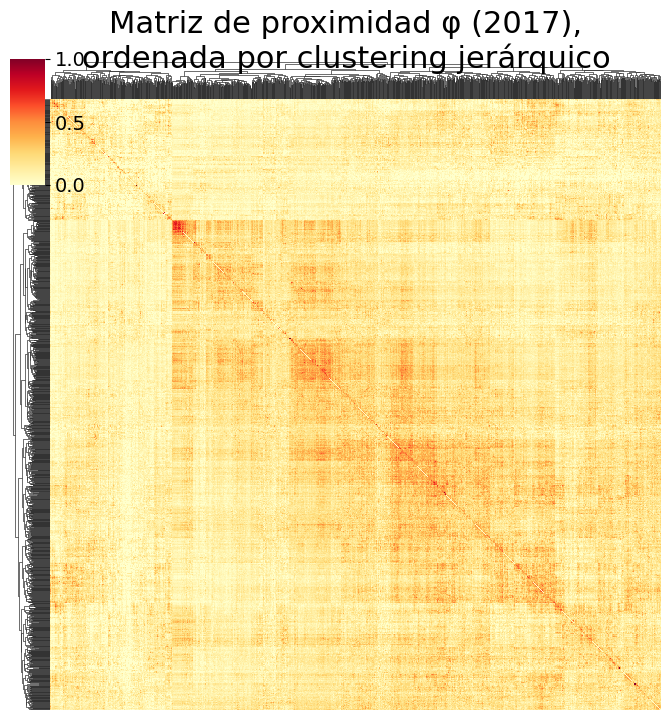

In [6]:
# =============================================================================
# Figura 2A: matriz de proximidad ordenada por clustering jerárquico
# =============================================================================
# El clustering jerárquico reordena filas y columnas agrupando productos con
# proximidades parecidas. Si el espacio de producto fuera homogéneo (todos los
# productos igual de cerca entre sí), el heatmap tendría un color parejo. Si
# aparecen bloques, hay grupos de productos que comparten capacidades entre sí
# y poco con el resto: la red es modular, y moverse entre bloques es difícil.
g = sns.clustermap(phi_matrix, cmap='YlOrRd', figsize=(7, 7),
                   xticklabels=False, yticklabels=False,
                   dendrogram_ratio=(0.06, 0.06))
g.fig.suptitle('Matriz de proximidad φ (2017),\nordenada por clustering jerárquico',
               y=1.05, fontsize=22)
g.ax_heatmap.set_xlabel('')
g.ax_heatmap.set_ylabel('')
g.ax_cbar.tick_params(labelsize=14)
g.savefig('/content/fig_phi_heatmap_2017.png', dpi=200, bbox_inches='tight')

Red completa: 1243 nodos, 731051 enlaces
Árbol de expansión máxima: 1242 enlaces
Backbone (árbol + φ >= 0,55): 1243 nodos, 1551 enlaces


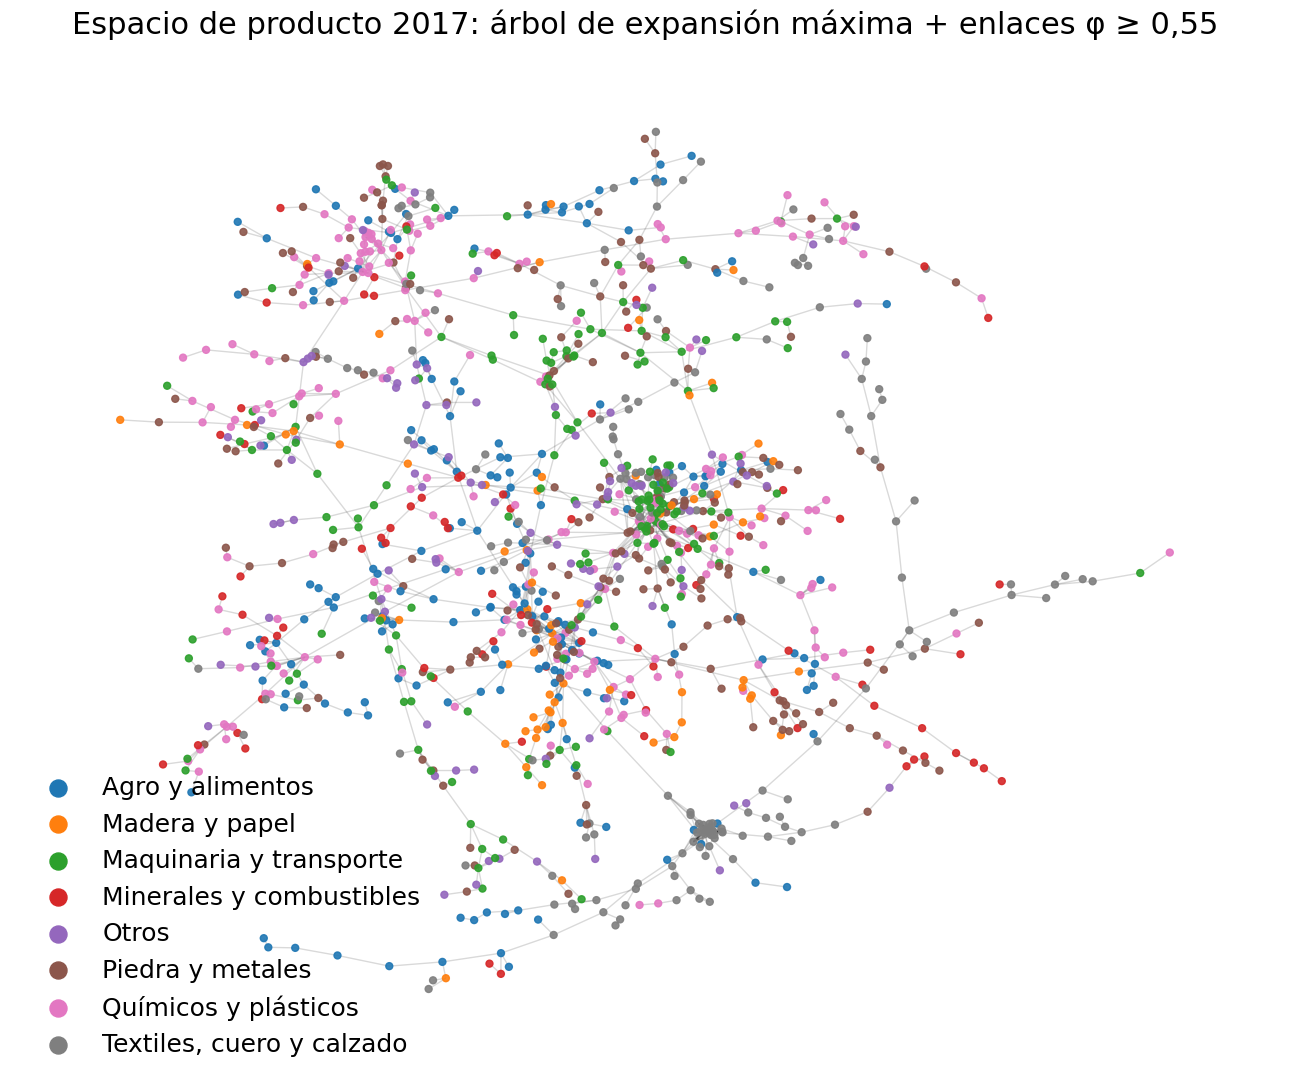

In [7]:
# =============================================================================
# Figura 2B: backbone del espacio de producto (árbol + φ >= 0,55)
# =============================================================================
# La red completa es casi un grafo completo (94,7 % de los pares con φ > 0), así
# que dibujada entera no se ve nada. Como en Hidalgo et al., se muestra un
# esqueleto: el árbol de expansión máxima (conecta los 1243 productos usando los
# vínculos más fuertes) más todos los enlaces con φ >= 0,55.
# Los nodos se colorean por grandes grupos de productos del Sistema Armonizado,
# como Hidalgo et al. lo hacen con la clasificación de Leamer.
# El backbone se usa solo para dibujar; todos los cálculos usan la matriz φ completa.

aristas = prox_2017[prox_2017['proximity'] > 0].rename(columns={'proximity': 'weight'})
GP = nx.from_pandas_edgelist(aristas, 'prod_1', 'prod_2', edge_attr='weight')
print("Red completa:", GP.number_of_nodes(), "nodos,", GP.number_of_edges(), "enlaces")

mst = nx.maximum_spanning_tree(GP, weight='weight')
fuertes = [(u, v, d) for u, v, d in GP.edges(data=True) if d['weight'] >= 0.55]

PS = nx.Graph()
PS.add_edges_from(mst.edges(data=True))
PS.add_edges_from(fuertes)
print("Árbol de expansión máxima:", mst.number_of_edges(), "enlaces")
print("Backbone (árbol + φ >= 0,55):", PS.number_of_nodes(), "nodos,", PS.number_of_edges(), "enlaces")

# Secciones del Sistema Armonizado, según los dos primeros dígitos del código
def seccion_hs(cod):
    if not cod[:2].isdigit():
        return 'Sin clasificar'                          # códigos tipo 'XXXX' de la base
    c = int(cod[:2])
    tramos = [(5, 'I Animales'), (14, 'II Vegetales'), (15, 'III Grasas y aceites'),
              (24, 'IV Alimentos y bebidas'), (27, 'V Minerales y combustibles'),
              (38, 'VI Químicos'), (40, 'VII Plásticos y caucho'), (43, 'VIII Cueros'),
              (46, 'IX Madera'), (49, 'X Papel'), (63, 'XI Textiles'), (67, 'XII Calzado'),
              (70, 'XIII Piedra, cerámica y vidrio'), (71, 'XIV Metales preciosos'),
              (83, 'XV Metales comunes'), (85, 'XVI Maquinaria y eléctricos'),
              (89, 'XVII Transporte'), (92, 'XVIII Instrumentos'), (93, 'XIX Armas'),
              (96, 'XX Manufacturas diversas'), (99, 'XXI Arte y otros')]
    return next(nom for tope, nom in tramos if c <= tope)

# Grandes grupos, para que la figura se pueda leer (como los grupos de Leamer en el paper)
grupos = {
    'I': 'Agro y alimentos', 'II': 'Agro y alimentos', 'III': 'Agro y alimentos', 'IV': 'Agro y alimentos',
    'V': 'Minerales y combustibles', 'XIV': 'Minerales y combustibles',
    'VI': 'Químicos y plásticos', 'VII': 'Químicos y plásticos',
    'VIII': 'Textiles, cuero y calzado', 'XI': 'Textiles, cuero y calzado', 'XII': 'Textiles, cuero y calzado',
    'IX': 'Madera y papel', 'X': 'Madera y papel',
    'XIII': 'Piedra y metales', 'XV': 'Piedra y metales',
    'XVI': 'Maquinaria y transporte', 'XVII': 'Maquinaria y transporte',
}
def grupo(cod):
    return grupos.get(seccion_hs(cod).split(' ')[0], 'Otros')

nombres = sorted(set(grupo(n) for n in PS.nodes()))
paleta = dict(zip(nombres, plt.cm.tab10.colors))
node_color = [paleta[grupo(n)] for n in PS.nodes()]

fig, ax = plt.subplots(figsize=(13, 11))
pos = nx.spring_layout(PS, seed=11, k=0.15, weight='weight')
nx.draw_networkx_edges(PS, pos, alpha=0.15, ax=ax)
nx.draw_networkx_nodes(PS, pos, node_color=node_color, node_size=25, alpha=0.9, ax=ax)
for nom, col in paleta.items():
    ax.scatter([], [], color=col, label=nom, s=150)
ax.legend(loc='lower left', fontsize=18, frameon=False)
ax.set_title("Espacio de producto 2017: árbol de expansión máxima + enlaces φ ≥ 0,55", fontsize=22)
ax.axis("off")
plt.tight_layout()
fig.savefig('/content/product_space_2017_backbone.png', dpi=200, bbox_inches='tight')
plt.show()

Se mantiene el backbone de Hidalgo et al. (MST más enlaces con φ ≥ 0,55) por fidelidad a la replicación. El núcleo más denso del mapa, está formado sobre todo por maquinaria y transporte (verde) y por piedra y metales (marrón), mezclados con algunos químicos y productos de madera. En el medio hay una segunda zona densa que combina agro, metales, químicos y madera. Los textiles (gris) forman su propio grupo denso abajo a la derecha, separado del núcleo, y se extienden en ramas largas hacia la derecha y hacia abajo. Los minerales y combustibles (rojo) aparecen en cadenas hacia el borde derecho y en puntos sueltos en la periferia, y el agro (azul) forma una rama larga abajo a la izquierda, además de puntos dispersos en los bordes. Los químicos y plásticos (rosa), en cambio, se reparten por todo el mapa sin concentrarse en el núcleo. En conjunto, la figura sugiere una estructura de centro y periferia como la del artículo: las manufacturas de maquinaria y metales en el centro, y los textiles, el agro y los minerales hacia afuera, con pocos caminos hacia el núcleo.

#Estabilidad del mapa

In [8]:
# =============================================================================
# Un espacio de producto por año (2005–2022), con los mismos países
# =============================================================================
# ¿el conflicto comercial y la pandemia (2018–2022) alteraron qué
# productos se exportan juntos? Para responderla se construye un φ por año.
# Todos los mapas usan los mismos países (los que exportan en todos los años),
# para que una diferencia entre años no se deba a la entrada o salida de países.

def mcp_anual(df):
    """Matriz binaria país x producto (RCA >= 1) para un año, sobre el universo de productos de 2017."""
    X = (df.pivot_table(index='loc', columns='prod', values='val', aggfunc='sum', fill_value=0)
           .reindex(columns=todos_los_productos, fill_value=0))
    share_pais = X.div(X.sum(axis=1), axis=0)            # peso del producto en la canasta del país
    share_mundo = X.sum(axis=0) / X.values.sum()         # peso del producto en el comercio total
    rca = share_pais.div(share_mundo, axis=1)
    return (rca >= 1).astype(np.float32).fillna(0).values

def phi_desde_mcp(M):
    """Proximidad φ (mínimo de las probabilidades condicionales), diagonal en cero."""
    U = M.T @ M                                          # co-ocurrencias producto x producto
    k = np.diag(U).copy()
    with np.errstate(divide='ignore', invalid='ignore'):
        cond = np.nan_to_num(U / k[:, None])             # P(RCA_j >= 1 | RCA_i >= 1)
    phi = np.minimum(cond, cond.T)
    np.fill_diagonal(phi, 0)
    return phi

# Verificación: con la M_cp de ecomplexity, la fórmula reproduce el φ de 2017
M17_ecx = (data_2017.pivot_table(index='loc', columns='prod', values='mcp', fill_value=0)
           .reindex(columns=todos_los_productos, fill_value=0).values.astype(np.float32))
print("Máxima diferencia con ecomplexity en 2017 (debe ser ~0):",
      np.abs(phi_desde_mcp(M17_ecx) - phi_matrix.values).max())

# Panel fijo de países: los que exportan algo en todos los años de la serie
años_por_pais = trade[trade['val'] > 0].groupby('loc')['year'].nunique()
paises_panel = sorted(años_por_pais[años_por_pais == len(AÑOS_SERIE)].index)
print(f"\nPaíses en el panel fijo: {len(paises_panel)}")

# Un mapa por año
mapas = {}
for año in AÑOS_SERIE:
    d = trade[(trade['year'] == año) & (trade['loc'].isin(paises_panel))]
    mapas[año] = phi_desde_mcp(mcp_anual(d))

iu = np.triu_indices(N, k=1)
print("\nProximidad media por año:")
for año in AÑOS_SERIE:
    print(f"  {año}: {mapas[año][iu].mean():.4f}")


# Mapa de 2017 con todos los países: es el que usa la sección de diversificación
A17 = phi_matrix.values

Máxima diferencia con ecomplexity en 2017 (debe ser ~0): 2.9495081932395806e-08

Países en el panel fijo: 223

Proximidad media por año:
  2005: 0.1542
  2006: 0.1544
  2007: 0.1531
  2008: 0.1573
  2009: 0.1540
  2010: 0.1544
  2011: 0.1568
  2012: 0.1568
  2013: 0.1572
  2014: 0.1545
  2015: 0.1509
  2016: 0.1494
  2017: 0.1515
  2018: 0.1529
  2019: 0.1508
  2020: 0.1517
  2021: 0.1521
  2022: 0.1529


Se arma un mapa por año, de 2005 a 2022, siempre con los mismos 223 países y los mismos 1243 productos. Así, si dos mapas son distintos, no es porque entró o salió un país, sino porque cambió qué productos se exportan juntos. Primero se chequea que el cálculo propio de la proximidad dé lo mismo que el paquete del Growth Lab: la diferencia es prácticamente cero, así que los 18 mapas están bien calculados.

Después se mira la proximidad media de cada año, es decir, qué tan seguido coinciden, en general, los productos en lo que exportan los países. Se mueve muy poco: entre 0,149 y 0,157. Sube en 2008, se mantiene alta entre 2011 y 2013 y baja entre 2014 y 2016, lo que coincide con el ciclo de precios de los productos básicos.


Distancias entre años consecutivos:
           Jaccard (local)  Polinomial (meso, x1e5)  Espectral cruda (global)  Espectral sin λ1 (global, %)
2005→2006           0.2272                   4.4283                    3.1563                        3.2366
2006→2007           0.2357                   4.6429                    2.8250                        2.5658
2007→2008           0.2312                   4.5660                    6.1592                        2.1653
2008→2009           0.2370                   4.6870                    5.6226                        3.4437
2009→2010           0.2338                   4.5425                    4.3994                        4.6435
2010→2011           0.2205                   4.3515                    4.3270                        2.2889
2011→2012           0.2165                   4.2962                    1.5710                        1.6434
2012→2013           0.2150                   4.2643                    1.3325                       

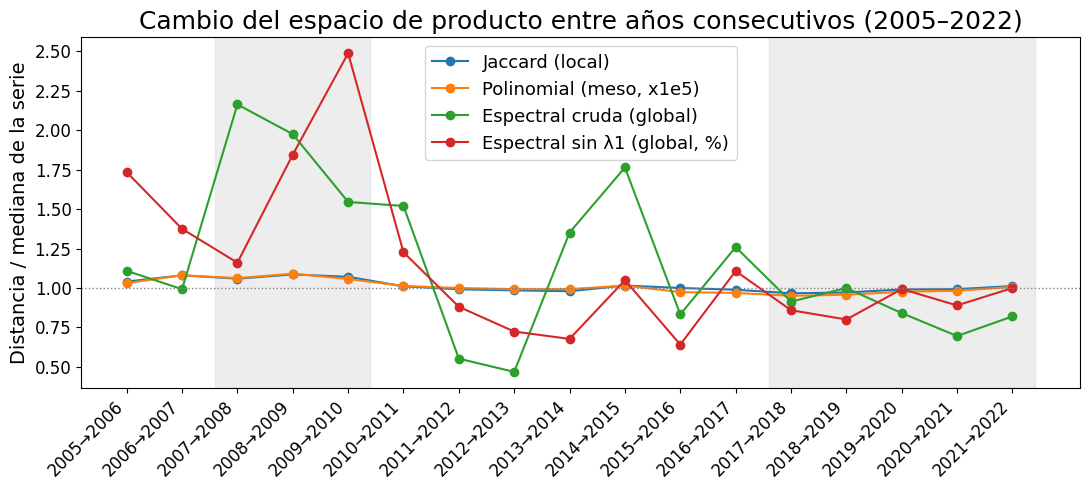

In [9]:
# =============================================================================
# Figura 1A: Distancias entre años consecutivos (2005→2006, ..., 2021→2022)
# =============================================================================
# Una distancia sola no dice si un cambio es grande o chico. La referencia es la
# propia serie: si los años de shocks muestran saltos claros respecto del resto,
# hubo un quiebre en el mapa.
# Tres escalas:
#   Jaccard con pesos (local): fracción de la "masa" de vínculos que cambió.
#   Polinomial (meso): incorpora caminos de longitud dos (A²).
#   Espectral (global): diferencia entre autovalores ordenados; cruda y sin el
#   mayor autovalor, que refleja el nivel promedio de φ y no la forma de la red.

espectros = {a: np.sort(np.linalg.eigvalsh(mapas[a].astype(np.float64))) for a in AÑOS_SERIE}
polis = {a: mapas[a].astype(np.float64) + (mapas[a].astype(np.float64) @ mapas[a].astype(np.float64)) / (N - 1)
         for a in AÑOS_SERIE}

def distancias(a, b):
    x, y = mapas[a][iu], mapas[b][iu]
    ea, eb = espectros[a], espectros[b]
    return {
        'Jaccard (local)': np.abs(x - y).sum() / np.maximum(x, y).sum(),
        'Polinomial (meso, x1e5)': 1e5 * np.linalg.norm(polis[a] - polis[b]) / N**2,
        'Espectral cruda (global)': np.linalg.norm(ea - eb),
        'Espectral sin λ1 (global, %)': 100 * np.linalg.norm(ea[:-1] - eb[:-1]) / np.linalg.norm(ea[:-1]),
    }

consec = pd.DataFrame({f"{a}→{a+1}": distancias(a, a + 1) for a in AÑOS_SERIE[:-1]}).T
print("Distancias entre años consecutivos:")
print(consec.round(4).to_string())

# Cada distancia dividida por su mediana en la serie: 1 = cambio típico de un año
relativo = consec / consec.median()
print("\nRespecto del cambio típico (mediana de la serie = 1):")
print(relativo.round(2).to_string())

fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(relativo))
for col in relativo.columns:
    ax.plot(x, relativo[col], 'o-', label=col)
ax.axhline(1, color='gray', ls=':', lw=1)
for ini, fin in [('2007→2008', '2009→2010'), ('2017→2018', '2021→2022')]:
    ax.axvspan(list(relativo.index).index(ini) - 0.4, list(relativo.index).index(fin) + 0.4,
               color='lightgray', alpha=0.4)
ax.set_xticks(x)
ax.set_xticklabels(relativo.index, rotation=45, ha='right', fontsize=12)
ax.tick_params(axis='y', labelsize=12)
ax.set_ylabel('Distancia / mediana de la serie', fontsize=14)
ax.set_title('Cambio del espacio de producto entre años consecutivos (2005–2022)', fontsize=18)
ax.legend(fontsize=13)
plt.tight_layout()
fig.savefig('/content/fig_distancias_consecutivas.png', dpi=200, bbox_inches='tight')
plt.show()

Se compara el mapa de cada año con el del año siguiente. Cada distancia se divide por el cambio de un año típico (la mediana de la serie). Un 1 es un año normal; un 2, el doble de lo normal. Las franjas grises marcan la crisis de 2008–2009 y el período de interes (2017–2022).
La polinomial (linea naranja) casi no se ve porque queda pegada a la de Jaccard: en un mapa donde casi todos los productos están conectados, sumar los caminos indirectos no agrega información. Polinomial en el analisis formal no se tendra en cuenta.

Los resultados muestran:

Los vínculos entre productos (Jaccard) cambian casi lo mismo todos los años, y desde 2011 un poco menos que antes.

La forma del mapa (espectral sin λ1) cambió más entre 2005 y 2010, período que coincide con la expansión de las cadenas globales de valor y la crisis de 2008–2009. El mayor cambio es el de 2009 a 2010.

La espectral cruda salta en 2008, 2009 y 2015. Esos saltos no son cambios de forma: coinciden con los años en que la proximidad media sube o baja (ver la proximidad media por año, en la celda anterior). Por eso se usa la versión sin el mayor autovalor, que no incluye ese nivel general.

Entre 2017 y 2022, con el conflicto comercial y la pandemia, todas las medidas están en el valor de un año típico o por debajo. Año a año no aparece un quiebre.

In [10]:
# Mayor autovalor en 2017 y 2022, panel fijo
print("λ1 2017:", round(espectros[2017][-1], 1), "| λ1 2022:", round(espectros[2022][-1], 1))

# Peso del mayor autovalor en la distancia espectral, años consecutivos
pesos = [(espectros[a][-1] - espectros[a+1][-1])**2 / ((espectros[a] - espectros[a+1])**2).sum()
         for a in AÑOS_SERIE[:-1]]
print(f"Peso de λ1: mín {min(pesos)*100:.0f} %, máx {max(pesos)*100:.0f} %")

λ1 2017: 201.5 | λ1 2022: 205.5
Peso de λ1: mín 0 %, máx 90 %


El mayor autovalor mide el nivel general de conexión del mapa, no su forma. Entre 2017 y 2022 pasa de 201,5 a 205,5, porque las proximidades suben un poco en general. Su peso en la distancia espectral entre años seguidos va de casi nada a un 90 %, según el año: en algunos años la distancia mide la forma del mapa, y en otros casi solo ese nivel general. Por eso se lo excluye, para que la medida compare la forma y no el nivel general.

 separación  pares  Jaccard (local)  Espectral sin λ1 (global, %)
          1     17           0.2214                        2.1353
          2     16           0.2489                        2.6190
          3     15           0.2647                        2.8638
          4     14           0.2767                        3.2042
          5     13           0.2867                        3.3440
          6     12           0.2949                        3.5192
          7     11           0.3021                        3.7194
          8     10           0.3084                        3.7731
          9      9           0.3141                        3.5990
         10      8           0.3194                        3.6936
         11      7           0.3242                        3.7545
         12      6           0.3292                        3.5864
         13      5           0.3342                        3.6374
         14      4           0.3385                        3.3648
         1

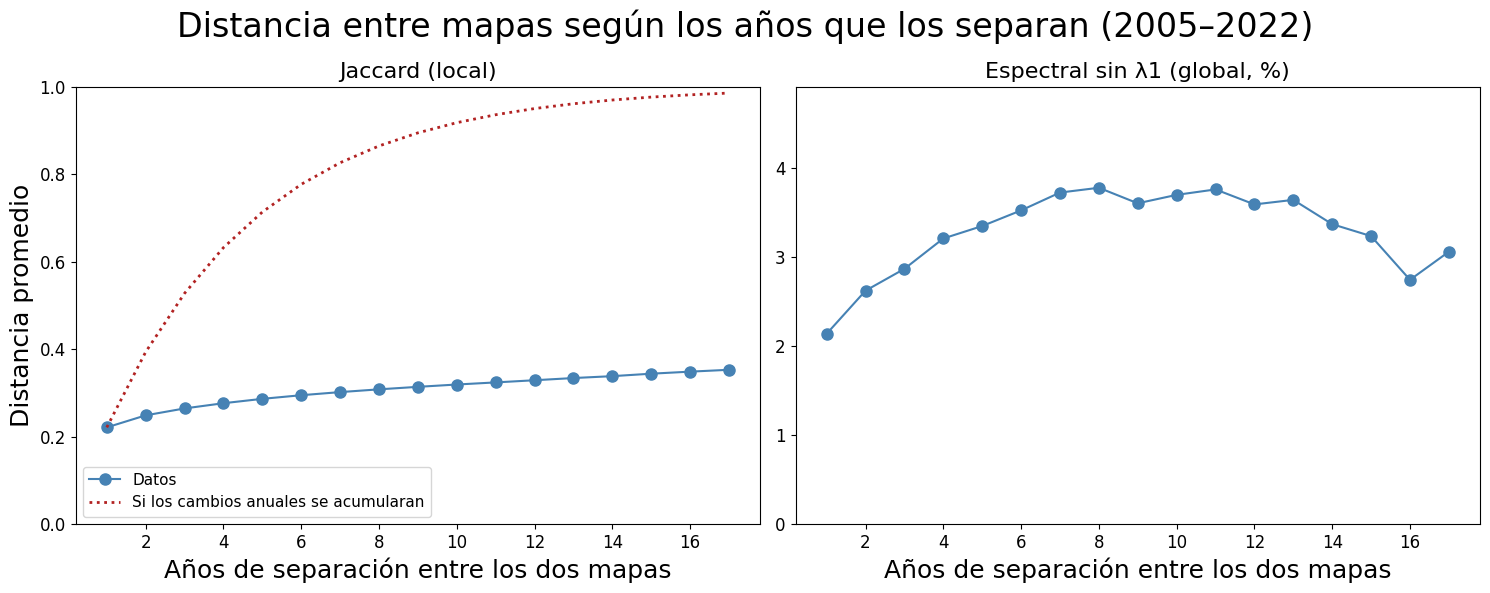

In [11]:
# =============================================================================
# Figura 1B: Distancia promedio según la separación entre años
# =============================================================================
# Compara mapas separados por 1, 2, 3... años y promedia sus distancias.
# Si los cambios de cada año se acumularan, la distancia crecería mucho con la
# separación; si en buena parte vuelven atrás, crece poco. Es la misma idea que
# muestra Hidalgo (2009), con distancias entre redes.
filas = []
for k in range(1, len(AÑOS_SERIE)):
    pares = [(a, a + k) for a in AÑOS_SERIE if a + k <= AÑOS_SERIE[-1]]
    ds = [distancias(a, b) for a, b in pares]
    filas.append({'separación': k, 'pares': len(pares),
                  'Jaccard (local)': np.mean([d['Jaccard (local)'] for d in ds]),
                  'Espectral sin λ1 (global, %)': np.mean([d['Espectral sin λ1 (global, %)'] for d in ds])})
sep = pd.DataFrame(filas)
print(sep.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, col in zip(axes, ['Jaccard (local)', 'Espectral sin λ1 (global, %)']):
    ax.plot(sep['separación'], sep[col], 'o-', color='steelblue', markersize=8, label='Datos')
    if col == 'Jaccard (local)':
        # Referencia: si el cambio de un año fuera permanente y se sumara año tras año
        k = sep['separación']
        d1 = sep.loc[sep['separación'] == 1, col].iloc[0]          # distancia con un año (≈ 0,22)
        ax.plot(k, 1 - (1 - d1) ** k, ':', color='firebrick', linewidth=2,
                label='Si los cambios anuales se acumularan')
        ax.set_ylim(0, 1)
        ax.legend(fontsize=11)                                     # leyenda solo en este panel
    else:
        ax.set_ylim(0, sep[col].max() * 1.3)
    ax.set_xlabel('Años de separación entre los dos mapas', fontsize=18)
    ax.set_title(col, fontsize=16)
    ax.tick_params(labelsize=12)
axes[0].set_ylabel('Distancia promedio', fontsize=18)
plt.suptitle('Distancia entre mapas según los años que los separan (2005–2022)', fontsize=24)
plt.tight_layout()
fig.savefig('/content/fig_distancia_separacion.png', dpi=200, bbox_inches='tight')
plt.show()

Si el mapa cambiara rápido, cuanto más separados estén dos años, más distintos serían sus mapas, y la distancia crecería con fuerza a medida que aumenta la separación (como la línea roja). Si no cambiara, la línea sería plana.

Panel de Jaccard : la línea sube, pero suave. La distancia crece de forma gradual: 0,22 con un año, 0,29 con cinco y 0,35 con diecisiete (una sola comparación). El mapa se reorganiza lento y sin saltos, y buena parte del cambio anual no se acumula.

Panel espectral (forma global del mapa): la distancia sube al principio y se estabiliza en una banda a partir de unos seis años. La forma general se mantiene, aunque cambien algunos vínculos.

El supuesto de Hidalgo et al. es que el mapa cambia lento, y esta figura muestra justamente eso: cambia, pero despacio, y la forma se mantiene.

In [12]:
# =============================================================================
# El quinquenio 2017–2022 frente a todos los quinquenios de la serie
# =============================================================================
# Responde la pregunta sin elegir un período de referencia a mano: si 2017→2022
# está entre los quinquenios que más cambiaron, el período de shocks alteró el
# mapa más que un quinquenio cualquiera.
q5 = pd.DataFrame({f"{a}→{a+5}": distancias(a, a + 5)
                   for a in AÑOS_SERIE if a + 5 <= AÑOS_SERIE[-1]}).T
q5 = q5[['Jaccard (local)', 'Espectral sin λ1 (global, %)']]
print(q5.round(4).to_string())
print("\nPosición de 2017→2022 (1 = el quinquenio que más cambió, de 13):")
print(q5.rank(ascending=False).loc['2017→2022'].astype(int).to_string())


# Media y desvio de quinquenios
print("\nMedia de los quinquenios:\n", q5.mean().round(3).to_string())
print("\nDesvío de los quinquenios:\n", q5.std().round(3).to_string())

           Jaccard (local)  Espectral sin λ1 (global, %)
2005→2010           0.2984                        3.5159
2006→2011           0.2951                        2.3391
2007→2012           0.2893                        3.4312
2008→2013           0.2858                        3.8252
2009→2014           0.2909                        5.8013
2010→2015           0.2861                        3.1102
2011→2016           0.2852                        2.1209
2012→2017           0.2814                        3.4910
2013→2018           0.2769                        3.5223
2014→2019           0.2820                        3.4227
2015→2020           0.2884                        3.5692
2016→2021           0.2850                        3.3389
2017→2022           0.2822                        1.9844

Posición de 2017→2022 (1 = el quinquenio que más cambió, de 13):
Jaccard (local)                 10
Espectral sin λ1 (global, %)    13

Media de los quinquenios:
 Jaccard (local)                 0.287


In [13]:
# Quinquenios ordenados según cuánto cambió la forma del mapa (1 = el que más cambió)
orden = q5.copy()
orden['puesto'] = orden['Espectral sin λ1 (global, %)'].rank(ascending=False, method='min').astype(int)
orden = (orden.sort_values('puesto')
              .reset_index()
              .rename(columns={'index': 'período'})
              [['puesto', 'período', 'Espectral sin λ1 (global, %)', 'Jaccard (local)']])
print(orden.round({'Espectral sin λ1 (global, %)': 2, 'Jaccard (local)': 3}).to_string(index=False))

 puesto   período  Espectral sin λ1 (global, %)  Jaccard (local)
      1 2009→2014                          5.80            0.291
      2 2008→2013                          3.83            0.286
      3 2015→2020                          3.57            0.288
      4 2013→2018                          3.52            0.277
      5 2005→2010                          3.52            0.298
      6 2012→2017                          3.49            0.281
      7 2007→2012                          3.43            0.289
      8 2014→2019                          3.42            0.282
      9 2016→2021                          3.34            0.285
     10 2010→2015                          3.11            0.286
     11 2006→2011                          2.34            0.295
     12 2011→2016                          2.12            0.285
     13 2017→2022                          1.98            0.282


Se toman todos los períodos de cinco años de la serie (2005–2010, 2006–2011, …, 2017–2022) y, en cada uno, se compara el mapa del primer año con el del último.

Los vínculos entre productos cambiaron casi lo mismo en todos los períodos, y el de 2017–2022 no se destaca (0,282, frente a un promedio de 0,287). En la forma del mapa, 2017–2022 da 1,98 %, frente a un promedio de 3,34 %. Es el valor más bajo, pero cercano al de otros períodos, como 2011–2016 (2,12 %), así que no indica que cambió menos, sino que no cambió más.. El que más cambió fue 2009–2014, después de la crisis.

Si el conflicto comercial y la pandemia hubieran cambiado qué productos se exportan juntos, 2017–2022 tendría que aparecer arriba de la tabla. No Aparece arriba. El mapa de 2017 sigue siendo una buena guía en 2022.

In [14]:
# =============================================================================
# Centralidad: ¿cambió qué productos ocupan el centro del mapa?
# =============================================================================
# Las distancias dicen cuánto cambió el mapa en conjunto, pero no si
# cambiaron los productos que ocupan su centro. Un producto central está cerca de
# muchos otros: un país que lo exporta tiene más productos relacionados a su alcance.
# Centralidad de autovector (Bonacich, 1972): un producto es central si está cerca
# de otros productos que también son centrales. Es el autovector del mayor
# autovalor de la matriz de proximidades.
# - Períodos: el inicio de la serie (2005–07), antes de los shocks (2015–17) y el
#   final (2020–22).
# - Se promedian los mapas de tres años por período, para suavizar el parpadeo de los vínculos débiles.
# - La centralidad se pasa a percentil dentro de cada período (1 = centro,
#   0 = periferia), para comparar posiciones aunque cambie el nivel general.

periodos = {'2005–07': [2005, 2006, 2007],
            '2015–17': [2015, 2016, 2017],
            '2020–22': [2020, 2021, 2022]}

cent_pct = pd.DataFrame(index=todos_los_productos)     # centralidad de autovector
fuerza_pct = pd.DataFrame(index=todos_los_productos)   # control: suma de proximidades
for nombre, años in periodos.items():
    phi_prom = np.mean([mapas[a] for a in años], axis=0).astype(np.float64)
    _, vecs = np.linalg.eigh(phi_prom)
    v1 = np.abs(vecs[:, -1])                            # el signo del autovector es arbitrario
    cent_pct[nombre] = pd.Series(v1, index=todos_los_productos).rank(pct=True)
    fuerza_pct[nombre] = pd.Series(phi_prom.sum(axis=1), index=todos_los_productos).rank(pct=True)

# Control: ¿autovector y suma de proximidades ordenan igual a los productos?
for nombre in periodos:
    rho = cent_pct[nombre].corr(fuerza_pct[nombre], method='spearman')
    print(f"{nombre}: Spearman autovector vs. suma de proximidades = {rho:.3f}")

# seccion_hs
cent_pct['seccion'] = [seccion_hs(p) for p in cent_pct.index]
cent_pct['cambio_largo'] = cent_pct['2020–22'] - cent_pct['2005–07']
cent_pct['cambio_reciente'] = cent_pct['2020–22'] - cent_pct['2015–17']

# 1) ¿Qué secciones ocupan el centro, y cambió?
por_seccion = (cent_pct.groupby('seccion')[['2005–07', '2015–17', '2020–22',
                                            'cambio_largo', 'cambio_reciente']]
               .mean().sort_values('2020–22', ascending=False))
por_seccion.insert(0, 'productos', cent_pct.groupby('seccion').size())
print("\nPercentil medio de centralidad por sección (1 = centro, 0 = periferia):")
print(por_seccion.round(2).to_string())

# 2) Los productos más centrales hoy
print("\nLos 15 productos más centrales en 2020–22:")
print(cent_pct.sort_values('2020–22', ascending=False)
      [['seccion', '2005–07', '2020–22']].head(15).round(2).to_string())

# 3) Mayores subas y bajas de centralidad (2005–07 → 2020–22)
print("\nMayores subas de centralidad:")
print(cent_pct.sort_values('cambio_largo', ascending=False)
      [['seccion', '2005–07', '2020–22', 'cambio_largo']].head(10).round(2).to_string())
print("\nMayores bajas de centralidad:")
print(cent_pct.sort_values('cambio_largo')
      [['seccion', '2005–07', '2020–22', 'cambio_largo']].head(10).round(2).to_string())

# 4) Estabilidad de la jerarquía: correlación de Spearman entre los rankings
print("\nCorrelación de Spearman de la centralidad entre períodos:")
print(cent_pct[['2005–07', '2015–17', '2020–22']].corr(method='spearman').round(3).to_string())

2005–07: Spearman autovector vs. suma de proximidades = 0.998
2015–17: Spearman autovector vs. suma de proximidades = 0.998
2020–22: Spearman autovector vs. suma de proximidades = 0.998

Percentil medio de centralidad por sección (1 = centro, 0 = periferia):
                                productos  2005–07  2015–17  2020–22  cambio_largo  cambio_reciente
seccion                                                                                            
VII Plásticos y caucho                 43     0.67     0.70     0.70          0.02            -0.00
XVI Maquinaria y eléctricos           133     0.59     0.63     0.63          0.04            -0.00
X Papel                                41     0.63     0.62     0.61         -0.02            -0.01
XIII Piedra, cerámica y vidrio         49     0.67     0.63     0.61         -0.05            -0.02
XIX Armas                               7     0.48     0.52     0.56          0.08             0.03
XV Metales comunes                    157

El centro está ocupado por manufacturas intermedias: piezas de caucho y plástico, artículos de hierro y aluminio, autopartes, tractores, maquinaria. Son productos que usan capacidades industriales generales (trabajar metales, moldear plásticos), que sirven para hacer muchas otras cosas. En la periferia están los minerales y combustibles, los metales preciosos y, dentro del agro, los vegetales y las grasas, que dependen de recursos naturales específicos y tienen pocos vecinos. Los productos animales y los alimentos procesados quedan en una posición intermedia.

Ese orden casi no cambió. Entre 2015–2017 y 2020–2022 da 0,92 y entre 2005–2007 y 2020–2022, quince años después, sigue siendo alta, 0,82. Los productos que estaban en el centro en 2005 siguen ahí en 2022. Ninguna sección se movió mucho. Los cambios grandes son de productos sueltos, lo que coincide con la digitalización de la música y el video, que se fueron a la periferia cuando la música y el video se volvieron digitales.

Las dos formas de medir la centralidad (estar cerca de productos centrales o simplemente de muchos productos) dan el mismo orden: la correlación de Spearman entre ambas es de 0,998 en los tres períodos, porque en este mapa casi todo está conectado.

#Diversificacion hacia productos cercanos

In [15]:
# =============================================================================
# Candidatos y su trayectoria 2017–2022
# =============================================================================
# Prueba de si los países se diversifican hacia productos
# que usan capacidades parecidas a las que ya tienen (principio de relatedness)
#
# Candidatos: pares país–producto con RCA < 0,5 en 2017 (el país claramente no
# lo exportaba con ventaja). En 2022 se clasifican como:
#   transición       RCA >= 1   (el país desarrolló ventaja comparativa)
#   no desarrollado  RCA < 0,5  (sigue sin exportarlo con ventaja)
#   inconcluso       el resto   (se descarta, como en Hidalgo et al.)
#   sin dato         el producto no figura en 2022
candidatos = (data_2017[data_2017['rca'] < 0.5][['loc', 'prod', 'rca']]
              .rename(columns={'rca': 'rca_2017'}))
rca_2022 = data_2022[['loc', 'prod', 'rca']].rename(columns={'rca': 'rca_2022'})
panel = candidatos.merge(rca_2022, on=['loc', 'prod'], how='left')

def clasificar(rca):
    if pd.isna(rca):
        return 'sin_dato'
    if rca >= 1:
        return 'transicion'
    if rca < 0.5:
        return 'no_desarrollado'
    return 'inconcluso'

panel['estado_2022'] = panel['rca_2022'].apply(clasificar)
print(panel['estado_2022'].value_counts())
print("\nCandidatos (RCA < 0,5 en 2017):", len(panel))

# Tasa de transición en cinco años, sobre los casos clasificables
n_validos = panel['estado_2022'].isin(['transicion', 'no_desarrollado']).sum()
print(f"Tasa de transición: {(panel['estado_2022'] == 'transicion').sum() / n_validos * 100:.1f} %")

estado_2022
no_desarrollado    227403
inconcluso           5999
transicion           5655
sin_dato              220
Name: count, dtype: int64

Candidatos (RCA < 0,5 en 2017): 239277
Tasa de transición: 2.4 %


Se arranca con los pares país–producto en los que el país exportaba ese producto poco o nada en 2017 (ventaja comparativa menor que 0,5): son 239.277 candidatos. En 2022 se mira qué pasó con cada uno. En 5655 casos el país pasó a exportarlo con ventaja comparativa (transición); en 227.403 siguió sin ventaja (no desarrollado); 5999 quedaron en una zona intermedia y se descartan, como en el paper de referencia. Y 220 no tienen dato en 2022.

La tasa de transición es del 2,4 %: de cada cien productos en los que un país no se destacaba en 2017, logró destacarse en dos en cinco años. Diversificarse es lento y difícil. La pregunta de los pasos siguientes es hacia qué productos lo hicieron: si estaban cerca de lo que ya exportaban con ventaja o no.

In [16]:
# =============================================================================
# Densidad ω (replica Hidalgo et al., 2007)
# =============================================================================
# ω_cj = sum_i M_ci φ_ij / sum_i φ_ij
# Es la fracción del "vecindario" del producto j que el país c ya exporta con
# ventaja comparativa en 2017, ponderando cada vecino por su proximidad.
# El denominador hace comparable la medida entre productos muy y poco conectados.

# M_cp de 2017: países x productos, 1 si RCA >= 1
Mcp_matrix = (data_2017.pivot_table(index='loc', columns='prod', values='mcp', fill_value=0)
              .reindex(columns=todos_los_productos, fill_value=0))
print("Mcp_matrix:", Mcp_matrix.shape)

def omega_panel(PHI):
    """ω para todos los pares país–producto (vectorizado) cruzado con el panel de candidatos."""
    with np.errstate(divide='ignore', invalid='ignore'):
        om = (Mcp_matrix.values @ PHI) / PHI.sum(axis=0)
    om = pd.DataFrame(om, index=Mcp_matrix.index, columns=todos_los_productos).stack().reset_index()
    om.columns = ['loc', 'prod', 'omega']
    return panel.merge(om, on=['loc', 'prod'], how='left')

panel_omega = omega_panel(A17)
print("Candidatos con ω calculado:", panel_omega['omega'].notna().sum(), "de", len(panel_omega))
print(panel_omega.groupby('estado_2022')['omega'].describe().round(3))

Mcp_matrix: (230, 1243)
Candidatos con ω calculado: 239277 de 239277
                    count   mean    std    min    25%    50%    75%    max
estado_2022                                                               
inconcluso         5999.0  0.175  0.113  0.002  0.083  0.153  0.255  0.539
no_desarrollado  227403.0  0.084  0.081  0.000  0.024  0.056  0.117  0.574
sin_dato            220.0  0.107  0.090  0.004  0.033  0.076  0.157  0.425
transicion         5655.0  0.114  0.086  0.003  0.048  0.092  0.154  0.497



Los productos en los que los países pasaron a tener ventaja comparativa tenían, en 2017, más vecinos ya exportados que los que siguieron sin ventaja: la densidad media es de 0,114 frente a 0,084, y la mediana, de 0,092 frente a 0,056. Los países se diversificaron hacia productos cercanos a lo que ya hacían. Los inconclusos, que avanzaron pero sin llegar a la ventaja comparativa, tienen la densidad más alta (0,175): también se movieron hacia productos cercanos.


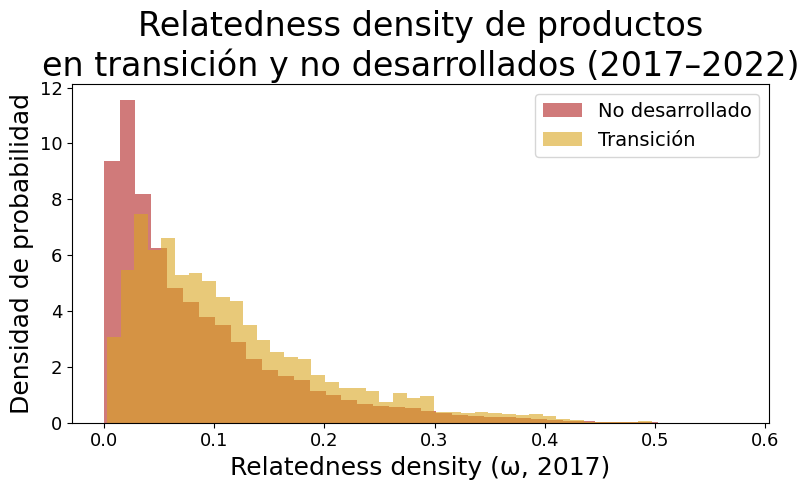

In [17]:
# =============================================================================
# Figura 3A: Relatedness Density ω, transiciones vs. no desarrollados
# =============================================================================
# Si las transiciones están desplazadas hacia la derecha, los países empezaron
# a exportar productos que ya tenían "cerca" en 2017: la diversificación siguió
# el camino de las capacidades existentes, como predice el principio de relatedness .
trans = panel_omega[panel_omega['estado_2022'] == 'transicion']['omega'].dropna()
no_dev = panel_omega[panel_omega['estado_2022'] == 'no_desarrollado']['omega'].dropna()

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(no_dev, bins=40, density=True, alpha=0.6, color='firebrick', label='No desarrollado')
ax.hist(trans, bins=40, density=True, alpha=0.6, color='goldenrod', label='Transición')
ax.set_xlabel('Relatedness density (ω, 2017)', fontsize=18)
ax.set_ylabel('Densidad de probabilidad', fontsize=18)
ax.set_title('Relatedness density de productos\nen transición y no desarrollados (2017–2022)', fontsize=24)
ax.tick_params(labelsize=13)
ax.legend(fontsize=14)
plt.tight_layout()
fig.savefig('/content/fig3A_omega_2017_2022.png', dpi=200, bbox_inches='tight')
plt.show()

Productos con H_j calculable: 1200 de 1243
% de productos con H_j > 1: 67.2 %


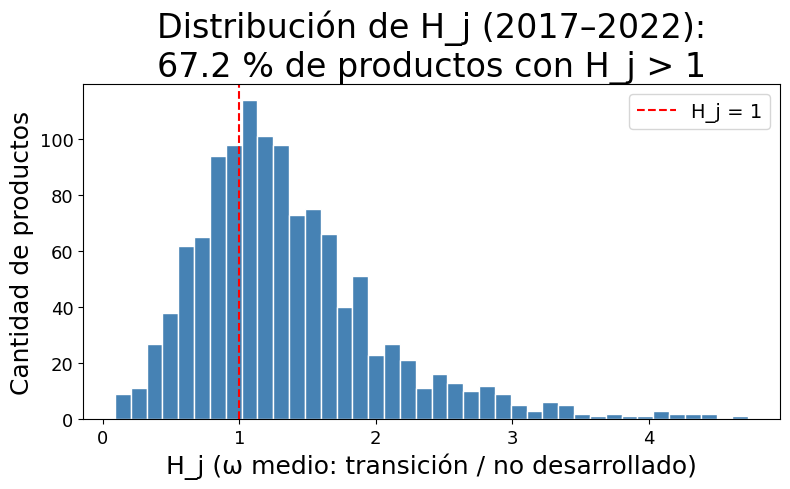

In [18]:
# =============================================================================
# Figura 3B: Razón H_j por producto
# =============================================================================
# H_j = ω medio de los países que transicionaron hacia j / ω medio de los que no
# lo desarrollaron. Se usan T_j y U_j (no N − T), porque los inconclusos se
# descartan. Solo se calcula para productos con al menos un país en cada grupo.
# Lectura económica: H_j > 1 significa que, para ese producto, los países que
# lo empezaron a exportar ya tenían más capacidades relacionadas que los que
# no lo lograron. Si esto pasa en la mayoría de los productos, el principio de
# relatedness se sostiene en 2017–2022.
def razon_H(panel_om):
    t = panel_om[panel_om['estado_2022'] == 'transicion'].groupby('prod')['omega'].mean()
    u = panel_om[panel_om['estado_2022'] == 'no_desarrollado'].groupby('prod')['omega'].mean()
    comunes = t.index.intersection(u.index)
    return (t[comunes] / u[comunes]).replace([np.inf, -np.inf], np.nan).dropna()

H_j = razon_H(panel_omega)
pct_mayor_a_1 = (H_j > 1).mean() * 100
print(f"Productos con H_j calculable: {len(H_j)} de {N}")
print(f"% de productos con H_j > 1: {pct_mayor_a_1:.1f} %")

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(H_j, bins=40, color='steelblue', edgecolor='white')
ax.axvline(1, color='red', ls='--', label='H_j = 1')
ax.set_xlabel('H_j (ω medio: transición / no desarrollado)', fontsize=18)
ax.set_ylabel('Cantidad de productos', fontsize=18)
ax.set_title(f'Distribución de H_j (2017–2022):\n{pct_mayor_a_1:.1f} % de productos con H_j > 1', fontsize=24)
ax.tick_params(labelsize=13)
ax.legend(fontsize=14)
plt.tight_layout()
fig.savefig('/content/fig3B_Hj_2017_2022.png', dpi=200, bbox_inches='tight')
plt.show()

                mean  count
bin_phi                    
(0.0, 0.1]  0.001966   2035
(0.1, 0.2]  0.005543  20928
(0.2, 0.3]  0.012792  59258
(0.3, 0.4]  0.025503  88264
(0.4, 0.5]  0.036883  50484
(0.5, 0.6]  0.050376   9985
(0.6, 0.7]  0.072159   1663
(0.7, 0.8]  0.085000    400
(0.8, 0.9]  0.200000     30
(0.9, 1.0]  0.090909     11

Tramo 0,5–0,6: 5.0 % (n = 9985)


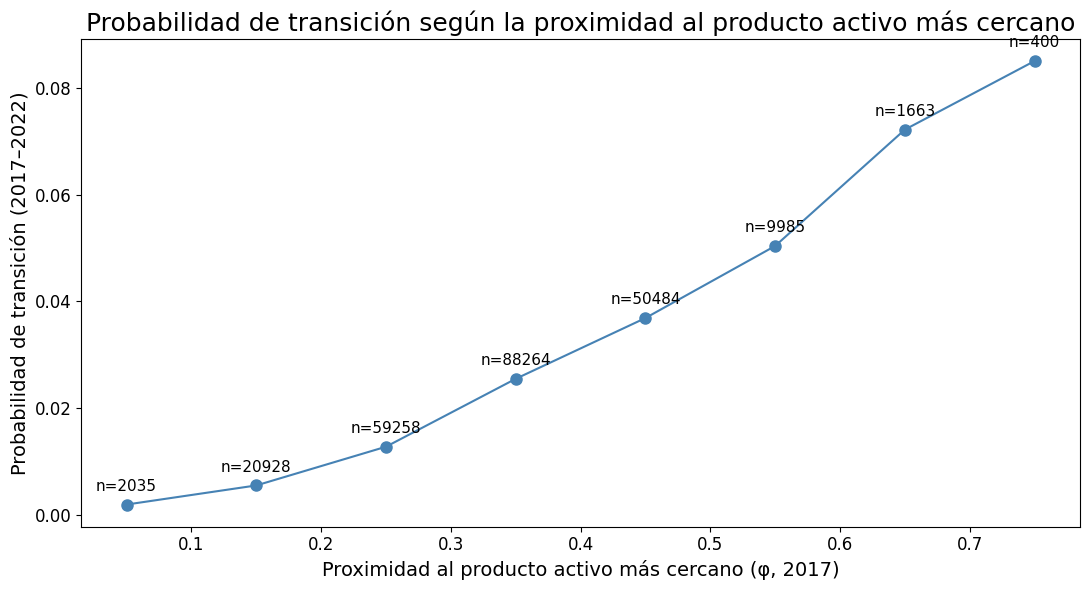

In [19]:
# =============================================================================
# Figura 3C: Proximidad al producto activo más cercano
# =============================================================================
# Para cada candidato se toma la máxima φ entre ese producto y los que el país
# ya exporta con RCA >= 1 en 2017: ¿qué tan cerca está mi vecino exportado más
# próximo? Se mide el salto más corto disponible.
# Lectura económica: si la probabilidad de lograr ventaja comparativa crece con
# esa proximidad, los saltos cortos son frecuentes y los largos, raros.
bins_phi = np.arange(0, 1.05, 0.1)

def vecino_cercano(PHI):
    M = Mcp_matrix.values.astype(bool)
    max_phi = np.full(M.shape, np.nan)
    for k in range(M.shape[0]):
        if M[k].any():                                  # países sin ningún producto con RCA>=1 quedan afuera
            max_phi[k] = PHI[:, M[k]].max(axis=1)
    vc = pd.DataFrame(max_phi, index=Mcp_matrix.index, columns=todos_los_productos).stack().reset_index()
    vc.columns = ['loc', 'prod', 'max_phi_vecino']
    pv = panel.merge(vc, on=['loc', 'prod'], how='left')
    pv = pv[pv['estado_2022'].isin(['transicion', 'no_desarrollado'])].copy()
    pv['transicionó'] = (pv['estado_2022'] == 'transicion').astype(int)
    pv['bin_phi'] = pd.cut(pv['max_phi_vecino'], bins=bins_phi)
    return pv

def tramo(pv, lo=0.5, hi=0.6):
    """Probabilidad de transición y n en (lo, hi]. Se usa 0,5–0,6 para comparar los
    controles porque es el tramo de proximidad alta con muchos casos (casi 10 mil)."""
    s = pv[(pv['max_phi_vecino'] > lo) & (pv['max_phi_vecino'] <= hi)]['transicionó']
    return s.mean(), len(s)

panel_vecino_valido = vecino_cercano(A17)
prob_transicion = (panel_vecino_valido.groupby('bin_phi', observed=False)['transicionó']
                   .agg(['mean', 'count']))
print(prob_transicion)
p, n = tramo(panel_vecino_valido)
print(f"\nTramo 0,5–0,6: {p*100:.1f} % (n = {n})")

prob_plot = prob_transicion.reset_index()
prob_plot['centro_bin'] = prob_plot['bin_phi'].apply(lambda x: x.mid)
# Los tramos 0,8–0,9 y 0,9–1,0 tienen solo 30 y 11 casos: su porcentaje depende de
# muy pocos países, así que no se dibujan (siguen en la tabla de arriba).
graf = prob_plot[prob_plot['count'] >= 100]

fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(graf['centro_bin'], graf['mean'], 'o-', color='steelblue', markersize=8)
for _, r in graf.iterrows():
    ax.annotate(f"n={int(r['count'])}", (r['centro_bin'], r['mean']),
                fontsize=11, textcoords="offset points", xytext=(0, 10), ha='center')
ax.set_xlabel('Proximidad al producto activo más cercano (φ, 2017)', fontsize=14)
ax.set_ylabel('Probabilidad de transición (2017–2022)', fontsize=14)
ax.set_title('Probabilidad de transición según la proximidad al producto activo más cercano', fontsize=18)
ax.tick_params(labelsize=12)
plt.tight_layout()
fig.savefig('/content/fig3C_probabilidad_2017_2022.png', dpi=200, bbox_inches='tight')
plt.show()

Los tramos de cercanía mayor que 0,8 tienen muy pocos casos (30 y 11) y no se tienen en cuenta

La línea sube de forma pareja: cuanto más cerca estaba el vecino exportado, más probable fue lograr el producto. Con un vecino lejano (cercanía menor que 0,1), lo logró el 0,2 % de los casos; con uno muy cercano (entre 0,7 y 0,8), el 8,5 %, unas cuarenta veces más. Es el mismo patrón que encuentran Hidalgo et al.: los saltos cortos son mucho más frecuentes que los largos.



Candidatos sin primarios: 181092 de 233058
                mean  count
bin_phi                    
(0.0, 0.1]  0.001239   1614
(0.1, 0.2]  0.005129  16378
(0.2, 0.3]  0.011952  45600
(0.3, 0.4]  0.024342  68894
(0.4, 0.5]  0.034387  38939
(0.5, 0.6]  0.048391   7832
(0.6, 0.7]  0.072727   1430
(0.7, 0.8]  0.088000    375
(0.8, 0.9]  0.272727     22
(0.9, 1.0]  0.125000      8

Tramo 0,5–0,6: todos 5.0 % | sin primarios 4.8 %


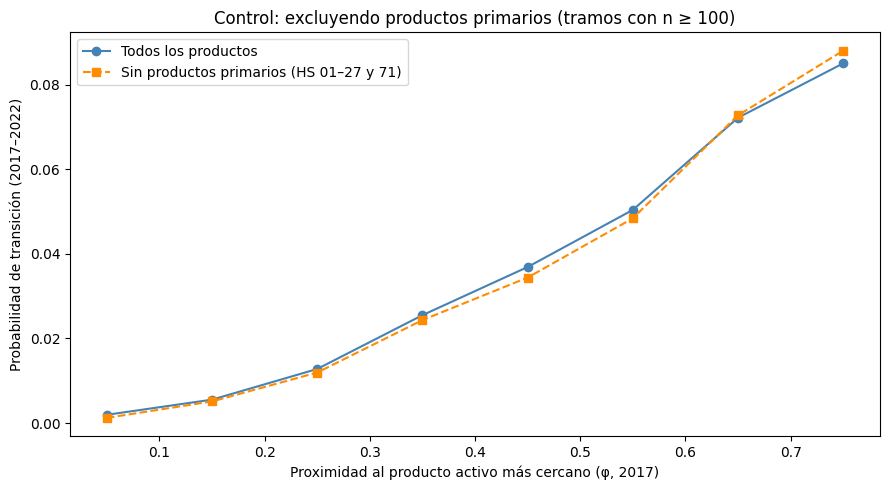

In [20]:
# =============================================================================
# Control: excluyendo productos primarios
# =============================================================================
# Los productos primarios (capítulos HS 01–27: agro, minerales y combustibles;
# y 71: metales preciosos) fueron los más afectados por el aumento de precios
# de 2021–22 (la tabla del control de calidad muestra que en 2022 el valor
# sube con registros casi estables, lo que sugiere un efecto de precios). Un alza de precios
# puede subir la RCA de un país sin que cambien sus capacidades. Si la
# probabilidad de transición sigue creciendo con la proximidad sin estos
# productos, el resultado no depende de ese shock.
cap = pd.to_numeric(panel_vecino_valido['prod'].str[:2], errors='coerce')
primarios = cap.le(27) | cap.eq(71)
sin_prim = panel_vecino_valido[~primarios]

print("Candidatos sin primarios:", len(sin_prim), "de", len(panel_vecino_valido))
prob_sin_prim = sin_prim.groupby('bin_phi', observed=False)['transicionó'].agg(['mean', 'count'])
print(prob_sin_prim)
print(f"\nTramo 0,5–0,6: todos {tramo(panel_vecino_valido)[0]*100:.1f} % | "
      f"sin primarios {tramo(sin_prim)[0]*100:.1f} %")

# Gráfico de control: todos vs. sin primarios, tramos con n >= 100
todos = prob_transicion.reset_index()
sinp = prob_sin_prim.reset_index()
todos['centro_bin'] = todos['bin_phi'].apply(lambda x: x.mid)
sinp['centro_bin'] = sinp['bin_phi'].apply(lambda x: x.mid)

fig, ax = plt.subplots(figsize=(9, 5))
t_ok, s_ok = todos['count'] >= 100, sinp['count'] >= 100
ax.plot(todos.loc[t_ok, 'centro_bin'], todos.loc[t_ok, 'mean'], 'o-',
        color='steelblue', label='Todos los productos')
ax.plot(sinp.loc[s_ok, 'centro_bin'], sinp.loc[s_ok, 'mean'], 's--',
        color='darkorange', label='Sin productos primarios (HS 01–27 y 71)')
ax.set_xlabel('Proximidad al producto activo más cercano (φ, 2017)')
ax.set_ylabel('Probabilidad de transición (2017–2022)')
ax.set_title('Control: excluyendo productos primarios (tramos con n ≥ 100)')
ax.legend()
plt.tight_layout()
fig.savefig('/content/fig3d_robustez_sin_primarios.png', dpi=200, bbox_inches='tight')
plt.show()

Las dos líneas casi se superponen. Sin los primarios, la probabilidad sigue creciendo con la cercanía de la misma manera; en el tramo 0,5–0,6, por ejemplo, es del 4,8 %, frente al 5,0 % con todos los productos. El resultado no depende del aumento de precios: la diversificación hacia productos cercanos también se da en las manufacturas.